# 🚗 Analyse des Auto-Datensatzes: Datenbereinigung, Feature Engineering & EDA

**Ziel:** Der Datensatz *Car Features & MSRP* (11.914 Einträge, 16 Spalten) wird bereinigt, transformiert und analysiert. Danach werden vier Fragestellungen beantwortet:

1. Welche Trends gibt es beim Preis (MSRP) in Abhängigkeit von der Fahrzeuggröße?
2. Wie hängt die Motorleistung (PS) mit dem Preis zusammen?
3. Gibt es einen signifikanten Preisunterschied zwischen den Antriebsarten?
4. Wie verändert sich der Verbrauch (MPG in Stadt und auf der Autobahn) je nach Getriebeart?

**Ablauf:** `Setup → Laden & Prüfen → Bereinigen → Feature Engineering → EDA (Statistik, Gruppen, Diagramme, Korrelation) → Fazit`

> **Hinweis:** Die Spaltennamen werden unverändert aus dem Originaldatensatz übernommen (englisch). *MPG* = Meilen pro Gallone (höher = sparsamer). *MSRP* = unverbindliche Preisempfehlung des Herstellers in US-Dollar.

## 0. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats

def de_num(x, nachkomma=2):
    """Zahl im deutschen Format: 1.234,56"""
    return f"{x:,.{nachkomma}f}".replace(",", "X").replace(".", ",").replace("X", ".")

pd.set_option("display.float_format", de_num)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid", context="notebook")
PALETTE = "crest"

# Läuft lokal (Projekt-Ordnerstruktur) und in Google Colab (lädt dann die Daten per URL)
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_PATH = PROJECT_ROOT / "data" / "raw" / "cars.csv"
PROCESSED_PATH = PROJECT_ROOT / "data" / "processed" / "cars_cleaned.csv"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_PATH.parent.mkdir(parents=True, exist_ok=True)
DATA_URL = ("https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/"
            "master/chapter-02-car-price/data.csv")

def save_fig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

usd = mtick.FuncFormatter(lambda x, _: f"{de_num(x, 0)} $")

## 1. Rohdaten laden & prüfen

In [2]:
raw = pd.read_csv(RAW_PATH if RAW_PATH.exists() else DATA_URL)
print(f"Größe: {de_num(raw.shape[0], 0)} Zeilen × {raw.shape[1]} Spalten")
raw.head()

Größe: 11.914 Zeilen × 16 Spalten


,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),"335,00","6,00",MANUAL,rear wheel drive,"2,00","Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),"300,00","6,00",MANUAL,rear wheel drive,"2,00","Luxury,Performance",Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),"300,00","6,00",MANUAL,rear wheel drive,"2,00","Luxury,High-Performance",Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),"230,00","6,00",MANUAL,rear wheel drive,"2,00","Luxury,Performance",Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),"230,00","6,00",MANUAL,rear wheel drive,"2,00",Luxury,Compact,Convertible,28,18,3916,34500


In [3]:
audit = pd.DataFrame({
    "Datentyp": raw.dtypes.astype(str),
    "fehlend": raw.isna().sum(),
    "fehlend_%": (raw.isna().mean() * 100).round(2),
    "eindeutig": raw.nunique(),
})
print(f"Exakte Duplikate: {raw.duplicated().sum()}")
audit.sort_values("fehlend", ascending=False)

Exakte Duplikate: 715


,Datentyp,fehlend,fehlend_%,eindeutig
Market Category,object,3742,"31,41",71
Engine HP,float64,69,"0,58",356
Engine Cylinders,float64,30,"0,25",9
Number of Doors,float64,6,"0,05",3
Engine Fuel Type,object,3,"0,03",10
Model,object,0,"0,00",915
Year,int64,0,"0,00",28
Make,object,0,"0,00",48
Driven_Wheels,object,0,"0,00",4
Transmission Type,object,0,"0,00",5


In [4]:
# Woher kommen die fehlenden PS- und Zylinderwerte?
print("Fehlende Engine HP nach Kraftstoffart:\n", raw.loc[raw["Engine HP"].isna(), "Engine Fuel Type"].value_counts(), "\n")
print("Fehlende Engine Cylinders nach Kraftstoffart:\n", raw.loc[raw["Engine Cylinders"].isna(), "Engine Fuel Type"].value_counts(), "\n")
print("Ausreißer bei highway MPG (> 150):")
raw.loc[raw["highway MPG"] > 150, ["Make", "Model", "Year", "highway MPG", "city mpg"]]

Fehlende Engine HP nach Kraftstoffart:
 Engine Fuel Type
electric                            44
regular unleaded                    14
flex-fuel (unleaded/natural gas)     6
premium unleaded (recommended)       4
diesel                               1
Name: count, dtype: int64 

Fehlende Engine Cylinders nach Kraftstoffart:
 Engine Fuel Type
premium unleaded (required)    17
electric                       10
regular unleaded                3
Name: count, dtype: int64 

Ausreißer bei highway MPG (> 150):


,Make,Model,Year,highway MPG,city mpg
1119,Audi,A6,2017,354,24


**Ergebnisse der Prüfung**

| Problem | Zeilen | Entscheidung |
|---|---|---|
| Exakte Duplikate | 715 | Entfernen. Sie würden Einträge in jedem Durchschnitt doppelt zählen. |
| `Market Category` fehlt | 3.742 (31 %) | Zu viele zum Löschen. „Keine besondere Kategorie“ ist eine sinnvolle Information, daher Auffüllen mit `"none"`. |
| `Engine HP` fehlt | 69 | Überwiegend Elektroautos. Auffüllen mit dem PS-Median in Stufen: gleiche *Marke + Modell*, dann *Marke + Kraftstoff*, dann *Kraftstoff + Fahrzeuggröße*, dann *Kraftstoff*. So bleiben Elektroautos im Datensatz, statt gelöscht zu werden. |
| `Engine Cylinders` fehlt | 30 | Elektroautos und Mazdas Wankelmotoren (RX-7/RX-8) haben **0** Zylinder. Für die übrigen der Modalwert derselben *Marke + Modell*. |
| MSRP für Baujahre ≤ 2000 | 772 nach dem Filter | Median ≈ 2.300 $, also keine echten Neuwagenpreise (eine bekannte Eigenheit dieses Datensatzes). Die Zeilen bleiben erhalten, werden aber mit `MSRP Placeholder` markiert und nur aus den **Preisanalysen** ausgeschlossen. |
| `Number of Doors` fehlt | 6 | Modalwert desselben *Modells*, sonst Modalwert des *Vehicle Style*. |
| `Engine Fuel Type` fehlt | 3 | Modalwert derselben *Marke + Modell*. |
| Audi A6 2017, `highway MPG` = 354 | 1 | Ein Tippfehler bei der Dateneingabe (city MPG beträgt 24). Korrektur auf 35. |
| `Transmission Type` = `UNKNOWN` | 19 | Die Zeilen bleiben erhalten und werden als `unknown` bezeichnet. Nur aus dem Getriebe-Diagramm ausgeschlossen. |

## 2. Datenbereinigung

In [5]:
df = raw.drop_duplicates().copy()

def group_fill(frame, col, by, how="median"):
    """Füllt fehlende Werte in `col` mit dem Median/Modalwert der Gruppe `by`."""
    if how == "median":
        filler = frame.groupby(by)[col].transform("median")
    else:
        filler = frame.groupby(by)[col].transform(
            lambda s: s.mode().iat[0] if not s.mode().empty else np.nan)
    return frame[col].fillna(filler)

# Kraftstoffart
df["Engine Fuel Type"] = group_fill(df, "Engine Fuel Type", ["Make", "Model"], how="mode")
df["Engine Fuel Type"] = df["Engine Fuel Type"].fillna("unknown")

# Zylinder: Elektroautos → 0, übrige → Modalwert des Modells
is_electric = df["Engine Fuel Type"].eq("electric")
df.loc[is_electric & df["Engine Cylinders"].isna(), "Engine Cylinders"] = 0
# Mazda RX-7 / RX-8 haben Wankelmotoren → keine Zylinder
is_rotary = df["Make"].eq("Mazda") & df["Model"].isin(["RX-7", "RX-8"])
df.loc[is_rotary & df["Engine Cylinders"].isna(), "Engine Cylinders"] = 0
df["Engine Cylinders"] = group_fill(df, "Engine Cylinders", ["Make", "Model"], how="mode")

# PS: Median nach Modell → Marke + Kraftstoff → Kraftstoff + Größe → Kraftstoff
df["Engine HP"] = group_fill(df, "Engine HP", ["Make", "Model"])
df["Engine HP"] = group_fill(df, "Engine HP", ["Make", "Engine Fuel Type"])
# Letzte Stufe (v. a. Elektroautos wie Tesla Model S / Nissan Leaf, für die in der Marke keine PS-Angabe existiert)
df["Engine HP"] = group_fill(df, "Engine HP", ["Engine Fuel Type", "Vehicle Size"])
df["Engine HP"] = group_fill(df, "Engine HP", ["Engine Fuel Type"])

# Anzahl Türen
df["Number of Doors"] = group_fill(df, "Number of Doors", ["Model"], how="mode")
df["Number of Doors"] = group_fill(df, "Number of Doors", ["Vehicle Style"], how="mode")

# Marktkategorie
df["Market Category"] = df["Market Category"].fillna("none")

# Tippfehler korrigieren
df.loc[df["highway MPG"] > 150, "highway MPG"] = 35

# Getriebe-Bezeichnung vereinheitlichen
df["Transmission Type"] = df["Transmission Type"].replace("UNKNOWN", "unknown")

before = len(df)
df = df.dropna(subset=["Engine HP", "Engine Cylinders", "Number of Doors"])
print(f"Gelöschte Zeilen (nicht auffüllbar): {before - len(df)}")
print("Verbleibende fehlende Werte:", int(df.isna().sum().sum()))

Gelöschte Zeilen (nicht auffüllbar): 0
Verbleibende fehlende Werte: 0


### 2.1 Filter (Baujahr ≥ 1995)

In [6]:
before = len(df)
df = df[df["Year"] >= 1995].copy()
print(f"{before - len(df)} Zeilen vor 1995 entfernt → {de_num(len(df), 0)} Zeilen verbleiben")

596 Zeilen vor 1995 entfernt → 10.603 Zeilen verbleiben


### 2.2 Textwerte vereinheitlichen

In [7]:
for col in ["Vehicle Style", "Market Category"]:
    df[col] = df[col].str.strip().str.lower()

df[["Vehicle Style", "Market Category"]].drop_duplicates().head()

,Vehicle Style,Market Category
0,coupe,"factory tuner,luxury,high-performance"
1,convertible,"luxury,performance"
2,coupe,"luxury,high-performance"
3,coupe,"luxury,performance"
4,convertible,luxury


### 2.3 Datentypen umwandeln

In [8]:
int_cols = ["Year", "Engine Cylinders", "Number of Doors", "highway MPG", "city mpg", "Popularity", "MSRP"]
df[int_cols] = df[int_cols].astype("int64")
df["Engine HP"] = df["Engine HP"].astype("float64")

cat_cols = ["Make", "Engine Fuel Type", "Transmission Type", "Driven_Wheels",
            "Vehicle Size", "Vehicle Style", "Market Category"]
df[cat_cols] = df[cat_cols].astype("category")
df["Vehicle Size"] = df["Vehicle Size"].cat.reorder_categories(["Compact", "Midsize", "Large"], ordered=True)

df.dtypes

Make                 category
Model                  object
Year                    int64
Engine Fuel Type     category
Engine HP             float64
Engine Cylinders        int64
Transmission Type    category
Driven_Wheels        category
Number of Doors         int64
Market Category      category
Vehicle Size         category
Vehicle Style        category
highway MPG             int64
city mpg                int64
Popularity              int64
MSRP                    int64
dtype: object

## 3. Feature Engineering

In [9]:
df["Total MPG"] = (df["city mpg"] + df["highway MPG"]) / 2
df["Price per HP"] = df["MSRP"] / df["Engine HP"]

# Datenqualitäts-Markierung: MSRP-Werte vor 2001 sind in diesem Datensatz keine echten Listenpreise
df["MSRP Placeholder"] = df["Year"] <= 2000
price_df = df[~df["MSRP Placeholder"]]          # Grundlage für alle Preisanalysen
print(f"Zeilen mit verlässlichem MSRP: {de_num(len(price_df), 0)} von {de_num(len(df), 0)}")
med = df.groupby("MSRP Placeholder")["MSRP"].median()
print(f"MSRP-Median: Baujahr ≤ 2000 = {de_num(med[True], 0)} $, Baujahr > 2000 = {de_num(med[False], 0)} $")

df[["Make", "Model", "city mpg", "highway MPG", "Total MPG", "MSRP", "Engine HP", "Price per HP"]].head()

Zeilen mit verlässlichem MSRP: 9.831 von 10.603


MSRP-Median: Baujahr ≤ 2000 = 2.304 $, Baujahr > 2000 = 33.050 $


,Make,Model,city mpg,highway MPG,Total MPG,MSRP,Engine HP,Price per HP
0,BMW,1 Series M,19,26,"22,50",46135,"335,00","137,72"
1,BMW,1 Series,19,28,"23,50",40650,"300,00","135,50"
2,BMW,1 Series,20,28,"24,00",36350,"300,00","121,17"
3,BMW,1 Series,18,28,"23,00",29450,"230,00","128,04"
4,BMW,1 Series,18,28,"23,00",34500,"230,00","150,00"


In [10]:
df.to_csv(PROCESSED_PATH, index=False)
print(f"Bereinigter Datensatz gespeichert → {PROCESSED_PATH.relative_to(PROJECT_ROOT)}  "
      f"({de_num(df.shape[0], 0)} Zeilen × {df.shape[1]} Spalten)")

Bereinigter Datensatz gespeichert → data\processed\cars_cleaned.csv  (10.603 Zeilen × 19 Spalten)


## 4. Explorative Datenanalyse (EDA)

### 4.1 Deskriptive Statistik

In [11]:
num_cols = ["Engine HP", "MSRP", "Popularity", "highway MPG", "city mpg"]
summary = df[num_cols].agg(["mean", "median", "std"]).T
summary["skew"] = df[num_cols].skew()
# Die MSRP-Zeile verwendet nur verlässliche Preise (Baujahr > 2000)
summary.loc["MSRP"] = [*price_df["MSRP"].agg(["mean", "median", "std"]), price_df["MSRP"].skew()]
summary.columns = ["Mittelwert", "Median", "Standardabweichung", "Schiefe"]
summary

,Mittelwert,Median,Standardabweichung,Schiefe
Engine HP,"258,57","240,00","109,56","1,26"
MSRP,"47.392,34","33.050,00","63.781,66","11,65"
Popularity,"1.575,33","1.385,00","1.459,07","1,61"
highway MPG,"26,72","26,00","8,55","4,17"
city mpg,"19,83","18,00","9,37","7,01"


Der MSRP ist stark rechtsschief: Der Mittelwert liegt deutlich über dem Median, und einige Exoten kosten über 1 Mio. $. Deshalb verwenden die Preisdiagramme unten eine **logarithmische Skala**, und die Gruppenvergleiche zeigen neben dem Mittelwert auch den **Median**.

### 4.2 Gruppenanalyse (durchschnittlicher MSRP & Popularität)

In [12]:
def group_summary(col):
    g = (price_df.groupby(col, observed=True)
           .agg(MSRP_Mittelwert=("MSRP", "mean"), MSRP_Median=("MSRP", "median"),
                Popularität_Mittelwert=("Popularity", "mean"), Anzahl=("MSRP", "size")))
    return g.sort_values("MSRP_Mittelwert", ascending=False)

group_summary("Driven_Wheels")

,MSRP_Mittelwert,MSRP_Median,Popularität_Mittelwert,Anzahl
Driven_Wheels,,,,
rear wheel drive,"67.273,79","40.065,00","1.723,00",2700
all wheel drive,"60.639,43","41.850,00","1.517,77",2243
four wheel drive,"42.808,86","35.700,00","1.722,62",1119
front wheel drive,"26.627,09","25.240,00","1.437,04",3769


In [13]:
group_summary("Vehicle Size")

,MSRP_Mittelwert,MSRP_Median,Popularität_Mittelwert,Anzahl
Vehicle Size,,,,
Large,"62.065,97","42.552,50","1.860,80",2380
Midsize,"43.901,31","34.655,00","1.465,21",3737
Compact,"41.501,85","25.697,00","1.479,82",3714


In [14]:
group_summary("Engine Cylinders").sort_index()

,MSRP_Mittelwert,MSRP_Median,Popularität_Mittelwert,Anzahl
Engine Cylinders,,,,
0,"44.212,17","33.700,00","1.530,24",83
3,"14.830,00","14.545,00","726,06",18
4,"26.921,62","25.007,50","1.438,32",3848
5,"30.511,50","29.125,00","845,26",117
6,"39.903,33","35.642,50","1.727,42",3738
8,"70.717,48","51.650,00","1.653,11",1739
10,"188.209,77","191.900,00","1.829,06",65
12,"296.234,72","263.300,00","788,26",220
16,"1.757.223,67","1.705.769,00","820,00",3


### 4.3 Visualisierungen

**a) Verteilung von city MPG**

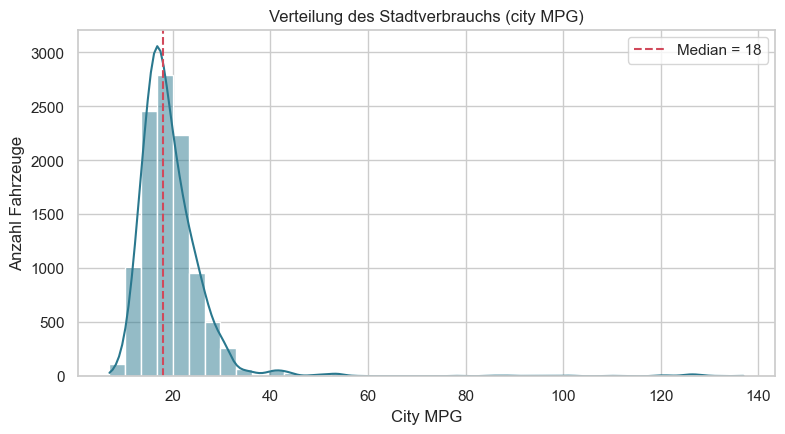

In [15]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(df["city mpg"], bins=40, kde=True, color="#2a788e", ax=ax)
ax.axvline(df["city mpg"].median(), color="#d1495b", ls="--", label=f"Median = {df['city mpg'].median():.0f}")
ax.set(title="Verteilung des Stadtverbrauchs (city MPG)", xlabel="City MPG", ylabel="Anzahl Fahrzeuge")
ax.legend()
save_fig(fig, "01_city_mpg_histogram"); plt.show()

**b) Durchschnittlicher MSRP nach Fahrzeuggröße** (Frage 1: Preis vs. Fahrzeuggröße)

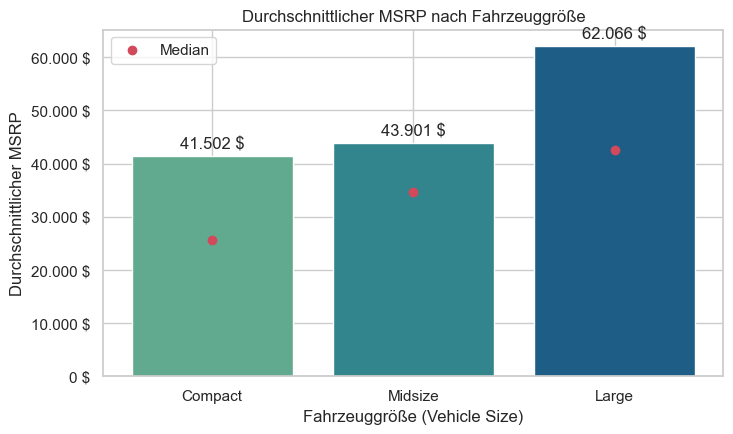

In [16]:
size_price = price_df.groupby("Vehicle Size", observed=True)["MSRP"].agg(["mean", "median"])
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(size_price.index.astype(str), size_price["mean"], color=sns.color_palette(PALETTE, 3))
ax.scatter(size_price.index.astype(str), size_price["median"], color="#d1495b", zorder=3, label="Median")
ax.bar_label(bars, labels=[f"{de_num(v, 0)} $" for v in size_price["mean"]], padding=3)
ax.yaxis.set_major_formatter(usd)
ax.set(title="Durchschnittlicher MSRP nach Fahrzeuggröße", xlabel="Fahrzeuggröße (Vehicle Size)",
       ylabel="Durchschnittlicher MSRP")
ax.legend()
save_fig(fig, "02_avg_msrp_by_vehicle_size"); plt.show()

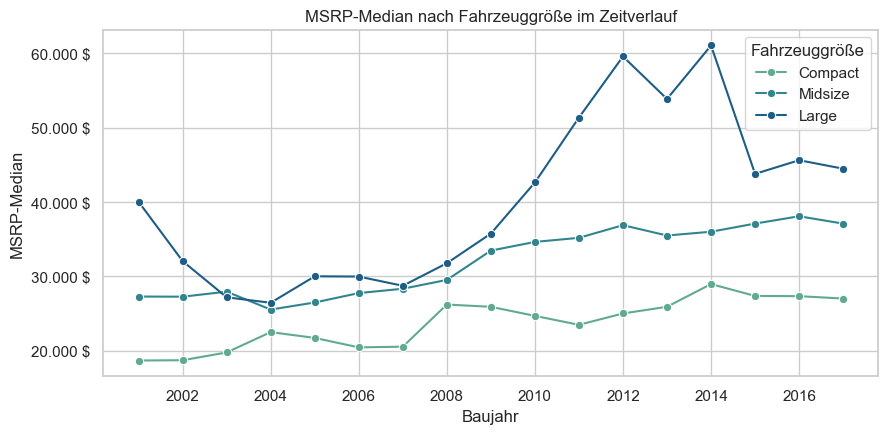

In [17]:
# Zusatz: Wie hat sich der Zusammenhang zwischen Größe und Preis im Zeitverlauf entwickelt?
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.lineplot(data=price_df, x="Year", y="MSRP", hue="Vehicle Size", estimator="median", errorbar=None,
             palette=PALETTE, marker="o", ax=ax)
ax.yaxis.set_major_formatter(usd)
ax.set(title="MSRP-Median nach Fahrzeuggröße im Zeitverlauf", xlabel="Baujahr", ylabel="MSRP-Median")
ax.legend(title="Fahrzeuggröße")
save_fig(fig, "02b_msrp_trend_by_size"); plt.show()

**c) Motorleistung (Engine HP) vs. MSRP** (Frage 2: PS vs. Preis)

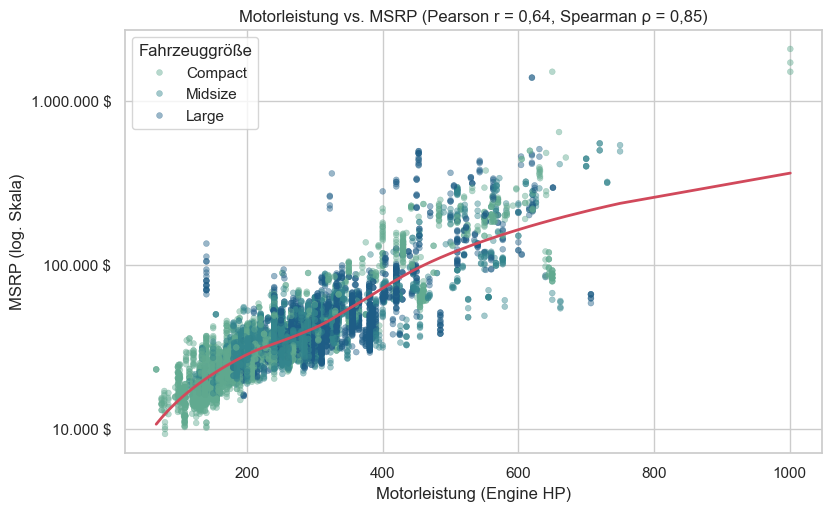

In [18]:
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.scatterplot(data=price_df, x="Engine HP", y="MSRP", hue="Vehicle Size", palette=PALETTE,
                alpha=0.45, s=18, edgecolor=None, ax=ax)
sns.regplot(data=price_df, x="Engine HP", y="MSRP", scatter=False, lowess=True,
            color="#d1495b", line_kws={"lw": 2, "label": "LOWESS-Trend"}, ax=ax)
ax.set_yscale("log"); ax.yaxis.set_major_formatter(usd)
r_p = price_df[["Engine HP", "MSRP"]].corr().iloc[0, 1]
r_s = price_df[["Engine HP", "MSRP"]].corr(method="spearman").iloc[0, 1]
ax.set(title=f"Motorleistung vs. MSRP (Pearson r = {de_num(r_p)}, Spearman ρ = {de_num(r_s)})",
       xlabel="Motorleistung (Engine HP)", ylabel="MSRP (log. Skala)")
ax.legend(loc="upper left", title="Fahrzeuggröße")
save_fig(fig, "03_hp_vs_msrp_scatter"); plt.show()

**d) MSRP-Verteilung nach Antriebsart** (Frage 3: Preis vs. Antrieb)

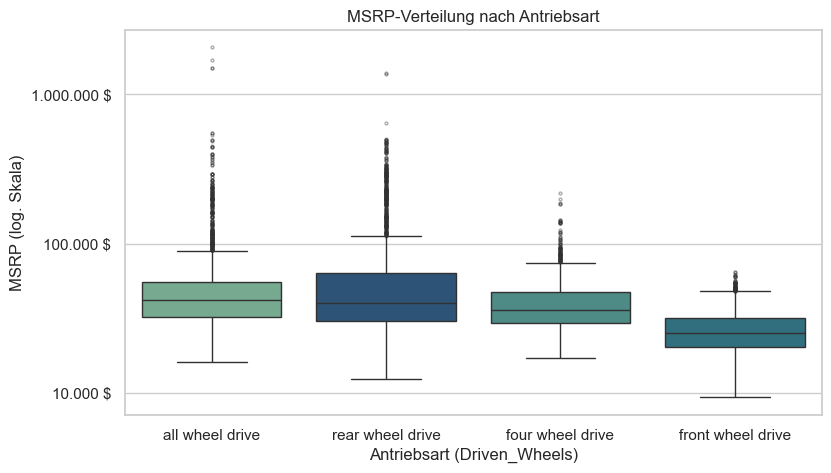

In [19]:
order = price_df.groupby("Driven_Wheels", observed=True)["MSRP"].median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=price_df, x="Driven_Wheels", y="MSRP", order=order, palette=PALETTE, hue="Driven_Wheels",
            legend=False, flierprops={"markersize": 2, "alpha": 0.4}, ax=ax)
ax.set_yscale("log"); ax.yaxis.set_major_formatter(usd)
ax.set(title="MSRP-Verteilung nach Antriebsart", xlabel="Antriebsart (Driven_Wheels)", ylabel="MSRP (log. Skala)")
save_fig(fig, "04_msrp_by_drivetrain_boxplot"); plt.show()

In [20]:
# Ist der Unterschied statistisch signifikant? MSRP ist nicht normalverteilt → Kruskal-Wallis-Test
# (nichtparametrische Alternative zur ANOVA)
groups = [g["MSRP"].values for _, g in price_df.groupby("Driven_Wheels", observed=True)]
h, p = stats.kruskal(*groups)
print(f"Kruskal-Wallis H = {de_num(h, 1)}, p {'< 1e-300' if p == 0 else f'= {p:.2e}'}")

# Paarweise Mann-Whitney-U-Tests mit Bonferroni-Korrektur
labels = list(order)
pairs = [(a, b) for i, a in enumerate(labels) for b in labels[i + 1:]]
rows = []
for a, b in pairs:
    u, pv = stats.mannwhitneyu(price_df.loc[price_df["Driven_Wheels"] == a, "MSRP"],
                               price_df.loc[price_df["Driven_Wheels"] == b, "MSRP"])
    rows.append({"Gruppe A": a, "Gruppe B": b, "p (Bonferroni)": min(pv * len(pairs), 1.0)})
pd.DataFrame(rows).assign(signifikant=lambda t: t["p (Bonferroni)"] < 0.05)

Kruskal-Wallis H = 2.946,7, p < 1e-300


,Gruppe A,Gruppe B,p (Bonferroni),signifikant
0,all wheel drive,rear wheel drive,"1,00",False
1,all wheel drive,four wheel drive,"0,00",True
2,all wheel drive,front wheel drive,"0,00",True
3,rear wheel drive,four wheel drive,"0,00",True
4,rear wheel drive,front wheel drive,"0,00",True
5,four wheel drive,front wheel drive,"0,00",True


**e) city & highway MPG nach Getriebeart** (Frage 4: Verbrauch vs. Getriebe)

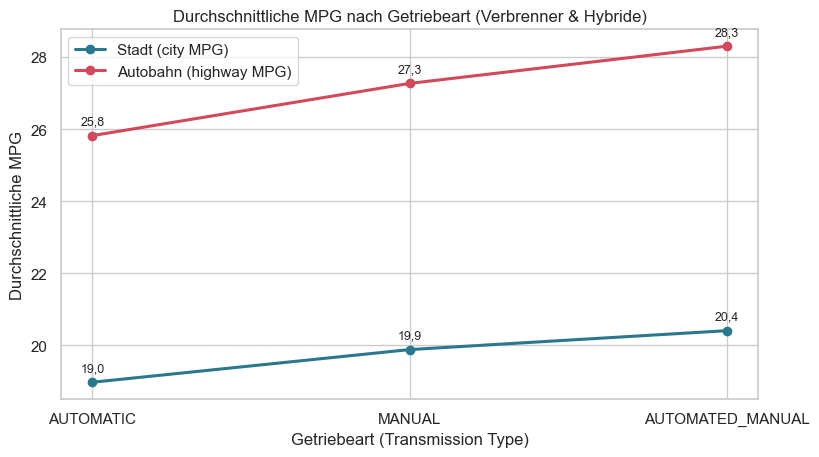

,city mpg,highway MPG
Transmission Type,,
AUTOMATIC,"18,98","25,82"
MANUAL,"19,88","27,27"
AUTOMATED_MANUAL,"20,41","28,30"


In [21]:
# Elektroautos werden in MPGe angegeben (≈ 100+) und sind nicht vergleichbar → separat unten
trans = (df[(df["Transmission Type"] != "unknown") & (df["Engine Fuel Type"] != "electric")]
           .groupby("Transmission Type", observed=True)[["city mpg", "highway MPG"]]
           .agg(["mean", "size"]))
trans = trans[trans[("city mpg", "size")] >= 30]           # sehr kleine Gruppen weglassen (nur 2 Nicht-E-Autos mit Direktantrieb)
trans = trans.xs("mean", axis=1, level=1).sort_values("highway MPG")
fig, ax = plt.subplots(figsize=(9, 4.8))
for col, color, label in [("city mpg", "#2a788e", "Stadt (city MPG)"), ("highway MPG", "#d1495b", "Autobahn (highway MPG)")]:
    ax.plot(trans.index.astype(str), trans[col], marker="o", lw=2.2, color=color, label=label)
    for x, y in zip(trans.index.astype(str), trans[col]):
        ax.annotate(de_num(y, 1), (x, y), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
ax.set(title="Durchschnittliche MPG nach Getriebeart (Verbrenner & Hybride)",
       xlabel="Getriebeart (Transmission Type)", ylabel="Durchschnittliche MPG")
ax.legend()
save_fig(fig, "05_mpg_by_transmission_line"); plt.show()
trans

`DIRECT_DRIVE` (Direktantrieb) besteht fast ausschließlich aus Elektroautos. Deren MPGe-Werte sind mit dem MPG von Verbrennern nicht vergleichbar. Deshalb schließt das Diagramm oben Elektroautos aus, und ihre Werte stehen separat in der Tabelle unten.

In [22]:
pd.concat({
    "Elektro (MPGe)": df[df["Engine Fuel Type"] == "electric"][["city mpg", "highway MPG"]].mean(),
    "alle ohne Elektro": df[df["Engine Fuel Type"] != "electric"][["city mpg", "highway MPG"]].mean(),
}, axis=1).T.round(1)

,city mpg,highway MPG
Elektro (MPGe),"112,70","99,60"
alle ohne Elektro,"19,30","26,30"


### 4.4 Korrelationsanalyse

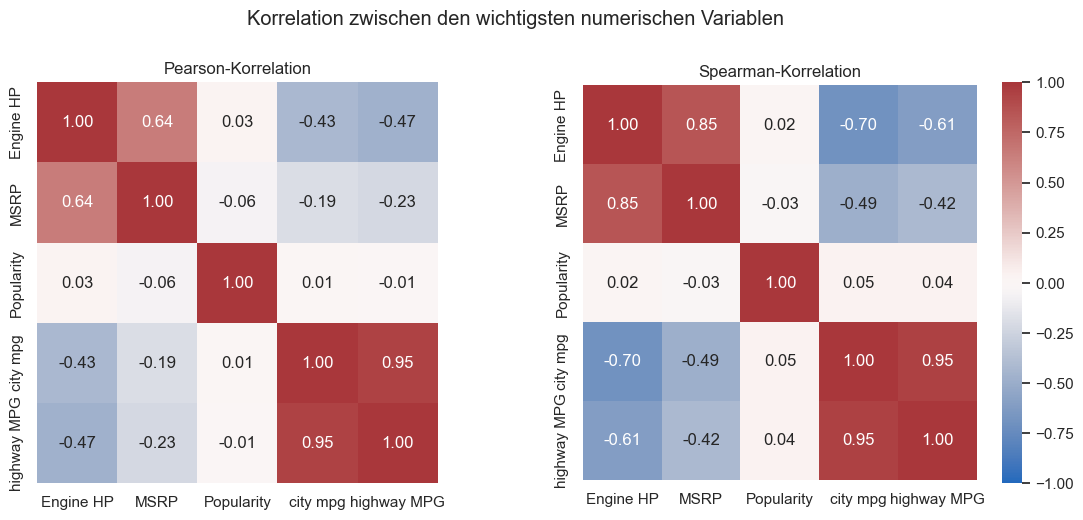

In [23]:
corr_cols = ["Engine HP", "MSRP", "Popularity", "city mpg", "highway MPG"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
for ax, method, name in zip(axes, ["pearson", "spearman"], ["Pearson", "Spearman"]):
    sns.heatmap(price_df[corr_cols].corr(method=method), annot=True, fmt=".2f", cmap="vlag",
                vmin=-1, vmax=1, square=True, cbar=ax is axes[1], ax=ax)
    ax.set_title(f"{name}-Korrelation")
fig.suptitle("Korrelation zwischen den wichtigsten numerischen Variablen", y=1.02)
save_fig(fig, "06_correlation_heatmap"); plt.show()

## 5. Kennzahlen für das Fazit

In [24]:
kennzahlen = {
    "Zeilen bereinigt": len(df),
    "Spearman PS–MSRP": price_df[["Engine HP", "MSRP"]].corr("spearman").iloc[0, 1],
    "Pearson PS–MSRP": price_df[["Engine HP", "MSRP"]].corr().iloc[0, 1],
    "Pearson highway–city MPG": df[["highway MPG", "city mpg"]].corr().iloc[0, 1],
    "Median Preis pro PS ($)": price_df["Price per HP"].median(),
    "Pearson PS–city MPG": df[["Engine HP", "city mpg"]].corr().iloc[0, 1],
    "Pearson Popularität–MSRP": price_df[["Popularity", "MSRP"]].corr().iloc[0, 1],
}
pd.Series(kennzahlen, name="Wert").to_frame()

,Wert
Zeilen bereinigt,"10.603,00"
Spearman PS–MSRP,"0,85"
Pearson PS–MSRP,"0,64"
Pearson highway–city MPG,"0,94"
Median Preis pro PS ($),"140,61"
Pearson PS–city MPG,"-0,40"
Pearson Popularität–MSRP,"-0,06"


## 6. Fazit

**Daten und Preise.** Nach dem Entfernen von 715 Duplikaten, dem Auffüllen fehlender Werte (es wurde keine Zeile gelöscht) und dem Filter auf Baujahre ab 1995 umfasst der bereinigte Datensatz **10.603 Fahrzeuge**. Ein Befund prägt alle weiteren Ergebnisse: Für Baujahre bis 2000 ist der MSRP nur ein Platzhalterwert (Median ≈ 2.300 $). Die Preisanalyse stützt sich deshalb auf die **9.831 Fahrzeuge ab Baujahr 2001**. Die Preise sind stark rechtsschief: Der Mittelwert liegt bei 47.400 $, der Median bei 33.100 $, mit einem langen Ausläufer von Exoten über 1 Mio. $. **Die Fahrzeuggröße bildet eine klare Preisstaffel.** Die Medianpreise liegen bei 25.700 $ für Kompaktwagen, 34.700 $ für Mittelklasse und 42.600 $ für große Fahrzeuge. Große Fahrzeuge sind zugleich das beliebteste Segment. Die Mittelwerte von Kompakt- und Mittelklasse liegen nur deshalb nah beieinander, weil die Kompaktklasse kleine, sehr teure Sportwagen enthält. **Die Motorleistung ist der stärkste Preistreiber** (Spearman ρ = 0,85, Pearson r = 0,64). Auf logarithmischer Preisskala ist der Zusammenhang nahezu linear: Jedes zusätzliche PS erhöht den Preis um einen etwa konstanten *Prozentsatz*. Die Zylinderzahl zeigt dasselbe Muster: Der Medianpreis steigt von 25.000 $ bei 4 Zylindern auf 52.000 $ bei 8 und 263.000 $ bei 12 Zylindern.

**Antrieb, Verbrauch und Popularität.** Der Preis unterscheidet sich signifikant zwischen den Antriebsarten (Kruskal-Wallis, p < 0,001). Frontantrieb ist klar am günstigsten (Median 25.200 $), gefolgt von Vierradantrieb (35.700 $). **Allradantrieb (41.900 $) und Heckantrieb (40.100 $) unterscheiden sich nach Bonferroni-Korrektur nicht signifikant voneinander.** Der Heckantrieb hat jedoch die mit Abstand größte Streuung, weil er Sport- und Luxuswagen umfasst. Bei Verbrennern und Hybriden **verändert die Getriebeart den Verbrauch nur wenig**. Automatisierte Schaltgetriebe sind am sparsamsten (20,4 Stadt / 28,3 Autobahn MPG), gefolgt von Schaltgetrieben (19,9 / 27,3) und Automatikgetrieben (19,0 / 25,8). Direktantrieb betrifft fast nur Elektroautos (≈ 113 / 100 MPGe). Diese sind nicht vergleichbar und werden separat ausgewiesen. Stadt- und Autobahnverbrauch hängen eng zusammen (r = 0,95), und beide sinken mit steigender Leistung (Spearman ρ = −0,70 für city MPG). **Die Popularität korreliert praktisch nicht mit Preis, Leistung oder Verbrauch** (|r| < 0,06). Der Datensatz enthält nur 48 verschiedene Popularitätswerte, einen pro Marke. Dieser Wert misst also die Beliebtheit der Marke, nicht die eines einzelnen Modells.